**Lab #2: Probability, Distributions, and Statistical Questions**

**Problem 1**

In lecture and homework we explored how the convolution can be used to calculate the probability of a sum or average. For this problem we are going to imagine that we are looking for gamma-ray sources (e.g. with the Fermi telescope). In this kind of telescope there is a background of cosmic-rays (electrons and protons, mostly) that provides a discrete noise term across the sky that precisely follows a Poisson distribution. To detect a gamma-ray source, you need to ask what is the probability that the cosmic-ray background would have given you a measurement as signal-like or more than the signal that you received.

To set up the problem, assume in 1 day the average cosmic-ray background is some number X (pick someting btwn 0.5 and 10, with different values for you and your lab partner); and the average number of gamma-rays emitted by your hypothetical source is Y (pick something larger than X).

In [26]:
import numpy as np
import scipy.stats as stats 
import matplotlib.pyplot as plt

# Parameters for ave. cosmic-ray background X and ave. number of gamma-rays emitted Y
# Y is larger than X

X = 4.0 # Average background counts per day
Y = 7.0 # Average source counts per day

print(f"Background rate X = {X} counts per day")
print(f"Source rate Y = {Y} counts per day")

Background rate X = 4.0 counts per day
Source rate Y = 7.0 counts per day


**A) Show how the probability distribution of the background changes as you integrate (sum) for more days.**

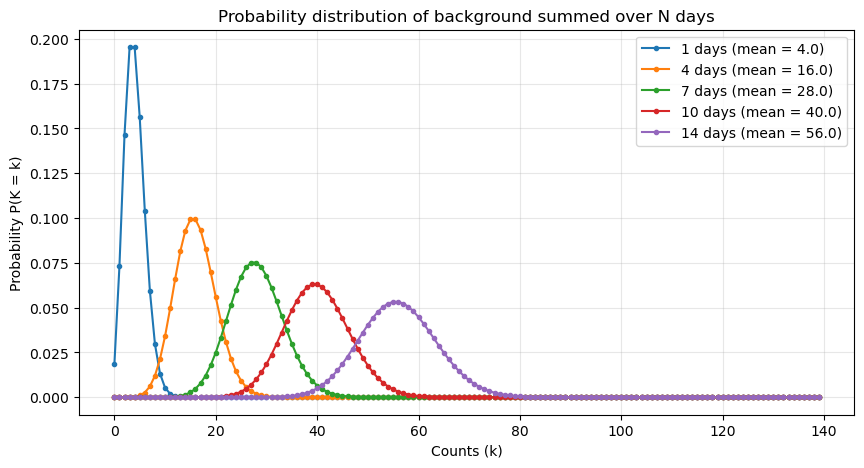

In [27]:
days = [1, 4, 7, 10, 14] # Array of days I'm using 
# Calculating max integer limit. 
k_max = int(max(days) * X * 2.5) # Multiplying largest valye in days array by X and 2.5 then rounding down. 
k_values = np.arange(0, k_max) # Sequence of integers from 0 up to k_max, stored in k_values. 

# Plot size
plt.figure(figsize = (10, 5))

# Looping through list of days and calculating expected rate for Poisson distribution over each span. 
# Probability mass function (pmf) is computed and plotted using matplotlib.
for N in days:
    lambda_N = N * X
    pmf = stats.poisson.pmf(k_values, lambda_N)
    plt.plot(k_values, pmf, marker = 'o', markersize = 3, linestyle = '-', label = f'{N} days (mean = {lambda_N})')

# Plotting details
plt.title("Probability distribution of background summed over N days")
plt.xlabel("Counts (k)")
plt.ylabel("Probability P(K = k)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

As we integrate for more days, the probability distribution of the background begins to shift towards the right (greater mean) and its spread broadens. This is because more summing accumulates more counts and so the expected rates scale linearly which means for $\lambda_N = N \times X$, the probability distribution is shifted and broadened. 

**B) Show that after 5 days, the summed probability distribution is still a Poisson distribution. Explain why this makes sense from a mathematical and conceptual point of view.**

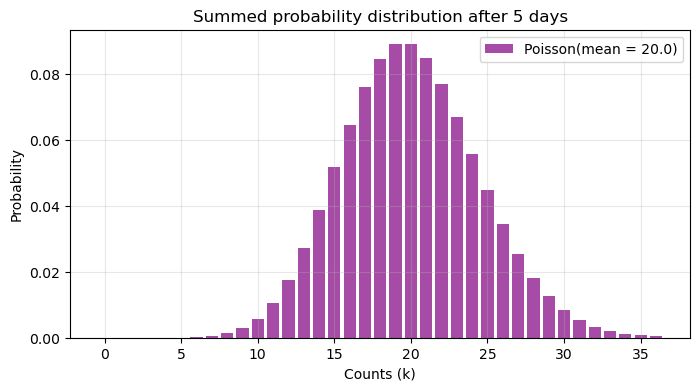

For N = 5 days, expected background = 20.0, variance = 20.0


In [28]:
N_b = 5 # Base count of 5 representing 5 days
lambda_5 = N_b * X # Calculating expected rate paramter for Poisson distribution
# Finding upper limit of k by getting mean and adding 4 times the standard deviation, Result is rounded down to whole number
k_max_b = int(lambda_5 + 4 * np.sqrt(lambda_5)) 
k_values_b = np.arange(0, k_max_b) # creating array of integers starting from 0 going up to K_values, stored. 

pmf_5 = stats.poisson.pmf(k_values_b, lambda_5) # probability mass function calculated

# Plotting 
plt.figure(figsize=(8, 4))
plt.bar(k_values_b, pmf_5, alpha=0.7, color='purple', label=f'Poisson(mean = {lambda_5})')
plt.title("Summed probability distribution after 5 days")
plt.xlabel("Counts (k)")
plt.ylabel("Probability")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"For N = 5 days, expected background = {lambda_5}, variance = {lambda_5}")

After 5 days, the summed probability distribution is still a Poisson distribution. 

Mathematically this makes sense because if we have two Poisson random variables $A$ and $B$ with corresponding rates of $\lambda_1$ and $\lambda_2$, their sum will also be a Poisson random variable of $A + B$ with a rate of $\lambda_1 + \lambda_2$. So summing $N$ daily background measurements where each is distributed as $\text{Poisson}(X)$ will result in $\text{Poisson}(N \times X)$, remaining a Poisson distribution. 

Conceptually, Poisson processes are describing discrete events that occur independently at a constant average rate. So if we take data over multiple days, this doesn't impact the independent events and just increases the window of observation. So the total count continues to follow a Poisson distribution. 

**C) Show how the probability distribution evolves as you average days. Calculate for many different ranges of days, and explore the shape of the distribution as the number of days becomes larger. Discuss this in relation to both B) and the central limit theoem.**

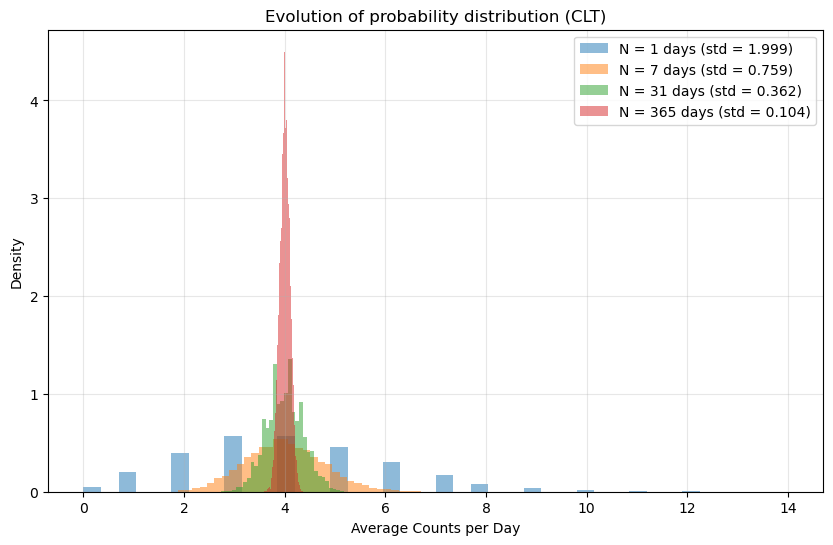

In [29]:
N_values = [1, 7, 31, 365] # Defining my list of days, going from 1 day up to a full year.
num_samples = 10000 # 10k trails repeating

plt.figure(figsize=(10, 6))

for N in N_values:
    # Random data following Poisson distribution is generated, with X being average rate of occurances. 
    simulated_days = np.random.poisson(X, size=(num_samples, N))
    # Calculating average outcome of N days. 
    averages = np.mean(simulated_days, axis=1)
    # plotting histogram, data into 40 bins, normalizing hist to area of 1, bars semi transparant
    # Plotting histogram, with data put in 40 bins, normalizing histogram to area of 1 and having bars appear transparant to view
    # even with overlapping present. 
    plt.hist(averages, bins=40, density=True, alpha=0.5, label=f'N = {N} days (std = {np.std(averages):.3f})')

# Plotting details
plt.title("Evolution of probability distribution (CLT)")
plt.xlabel("Average Counts per Day")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

When averaging $N$ days instead of summing them, the random variable is proportional to $1/N$. The Central Limit Theorem states that the sampling distribution of a sample mean approaches a normal distribution as the sample size increases. So when $N$ increases, it follows the CLT but the difference between averaging and summing from part B is that instead of summing increasing variance and widening the curve, the average has a variance that decreases as $1/N$ and causes the distribution to become more narrow and sharper around the mean. 

**D) Pick some number of days N, and assume you saw Y*N gamma rays from your source. Calculate the 'sigma' of your observation. [In reality the number of gamma-rays seen from a source will also fluctuate, but we're going to ignore that complication for a couple of labs.]**

In [30]:
N_obs = 7 # Number of days for observing.
# Calculating background noise events over defined observation period, multiplying bg rate X by obs period.
exp_bg = N_obs * X 
std_bg = np.sqrt(exp_bg) # Standard deviation of background events.

# gets total number of events recorded including the daily background X and potential new source's Y over obs period. 
obs_counts = (X + Y) * N_obs

# Calculating the sigma significance (Z-score), giving how many std dev data is from bg
sigma_sig = (obs_counts - exp_bg) / std_bg

print(f"Observation Period (N_obs): {N_obs} days")
print(f"Expected background counts: {exp_bg} counts")
print(f"Observed counts (Source + Background): {obs_counts}")
print(f"'Sigma' of Observation: {sigma_sig:.2f} sigma")

Observation Period (N_obs): 7 days
Expected background counts: 28.0 counts
Observed counts (Source + Background): 77.0
'Sigma' of Observation: 9.26 sigma


**Problem 2**

Pick a skewed continuous distribtuion, such as a Rayleigh, that describes your background over some observing interval.

**A) Show how the distribution changes as you average over more observing intervals.**

In [31]:
# Scale parameter for rayleigh distribution
scale_param = 2.0

print(f"Rayleigh scale parameter = {scale_param}")

Rayleigh scale parameter = 2.0


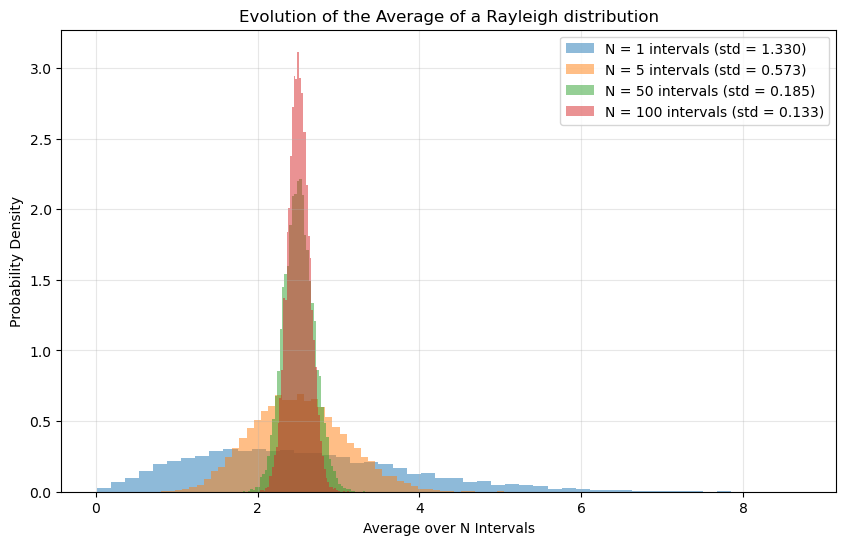

In [32]:
N_val = [1, 5, 50, 100] # Running 4 simulations using samples of N
num_samples = 10000 # Taking 10k samples in every simulation

plt.figure(figsize=(10, 6))

for N in N_val:
    # Generating 2D matrix of random numbers following a rayleigh distribution
    # and computing mean across the intervals
    sim_intervals = np.random.rayleigh(scale=scale_param, size=(num_samples, N))
    averages = np.mean(sim_intervals, axis=1) # Finding average for each
    # Plotting histogram of the averages, 50 bins for data, normalized to area of 1.
    plt.hist(averages, bins=50, density=True, alpha=0.5, label=f'N = {N} intervals (std = {np.std(averages):.3f})')

# Plotting parameters
plt.title("Evolution of the Average of a Rayleigh distribution")
plt.xlabel("Average over N Intervals")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**B) Discuss how the shape changes. Does it approach a Gaussian distribution? If yes, after how many intervals?**

The shape seems to be following the Central Limit Theorem prediction. It does approach a Gaussian distribution even though the rayleigh distribution is skewed to the right ($N=1$). The distribution becomes symmetric and bell shaped as we average and N grows larger. I'd say this begins to happen after about $5$ intervals, so maybe $10$ intervals? We can see that after $5$ intervals it starts to approach a Gaussian distribution pretty closely. 

**Problem 3**

The discovery of optical/infra-red counterparts of Neutron star mergers initially detected with gravity-waves is one of the great discoverys in the last few years (wikipedia, scientific paper), and has ushered in the age of "multi-messenger astrophysics." The science that can be done by matching a gravity-wave signal (directly measures the mass of the neutron stars and their distance) with the optical emisson (redshift, nuclear astrophysics of the resulting explosion) is staggering. Lots of science from how the heaviest elements are formed to constraints on Dark Energy.

We're going to explore one of the analysis questions that comes up when looking for the optical counterparts (a new optical source) of a gravity wave signal. For this problem let's assume that we are using an optical telescope with a thermal noise background from the CCD (dark current, particularly an issue with older CCDs and/or infra-red CCDs). After flat-fielding, the background appears as a zero-mean Gaussian with constant width over the image.

**Version 1**

You have an alert from LIGO that is also seen in with the X-ray/ultra-violet satellite SWIFT. SWIFT gives you a very precise location, so you take an image of that part of the sky. But because of SWIFT's accuracy, you know which pixel in your image to look for a counterpart in.

**A) From looking at all the other pixels in your image, you can measure the width of the background Gaussian distribution X (pick something). Assuming you see a signal of strength Y (pick a floating-point number; typical optical CCDs are not sensitive enough to count photons so the readings are floating point brightnesses, not integer photons). Calculate the significance of your detection. Can you claim a discovery (traditionally 5-sigma or more)?**

In [33]:
# Setting my parameters 
X = 4.0   # Width of bg gaussian distribution (std deviation)
Y = 7.0   # Signal strength

print(f"Background noise width X = {X}")
print(f"Source signal Y = {Y}")

Background noise width X = 4.0
Source signal Y = 7.0


In [34]:
# Calculating significance 
sigma_V1 = Y / X

print(f"Significance of detection: {sigma_V1:.2f} sigma")

# Checking significance value against 5 sigma threshold. Prints back result of whether or not it passes as a discovery. 
if sigma_V1 >= 5.0:
    print("Result is greater than or equal to 5 sigma, can claim a discovery.")
else:
    print("Result is less than 5 sigma, cannot claim a discovery yet.")

Significance of detection: 1.75 sigma
Result is less than 5 sigma, cannot claim a discovery yet.


Calculating the significance of my detection utilized the equation of the measured signal divided by the background noise standard deviation: $$\sigma = \frac{Y}{X}$$
My result yielded a significance of 1.75 sigma, so I cannot claim a discovery because it falls below the 5 sigma threshold. 

**Version 2**

You have an alert from LIGO, but no associated detection from SWIFT. This could be because it is a black hole-black hole merger, a black hole-neutron star merger (neither seem to emit X-rays or UV light), or it could because SWIFT was indisposed at the time (wrong side of the earth in its orbit). Whatever the cause, you know what region of the sky to look in, but not which pixel.

**B) If you have to look for a signal in 10k pixels, what is the probability distribution of your background? (Clearly state the statistical question, then turn that into math using your background distribution from part 1 of this problem.)**

Statistical Question: What is the probability that the max background noise in 10k independent pixels fluctuates to a value that is greater than or equal to our observed signal $Y = 7.0$?

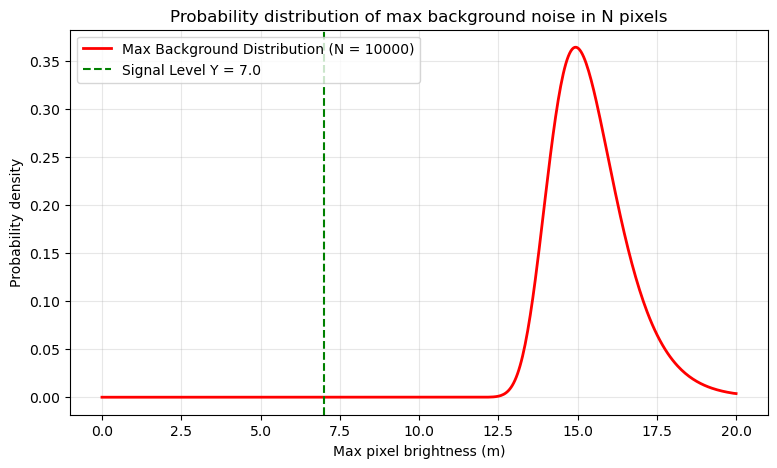

In [40]:
N_pixels = 10000 # Number of pixels

m_values = np.linspace(0, 5 * X, 500) # Array of 500 evenly spaced numbers going from 0 to 5 * X (range)
cdf_single = stats.norm.cdf(m_values, loc=0, scale=X) # Computing CDF for a single px, background noise follows gaussian distribution
cdf_max = cdf_single**N_pixels # Raising the CDF for a single px to the power of total px (10k)
pdf_max = np.gradient(cdf_max, m_values) # Calculating rate of change of max CDF relative to our array of numbers (m_values)

# Plotting parameters to visualize math occuring
plt.figure(figsize=(9, 5))
plt.plot(m_values, pdf_max, 'r-', linewidth = 2, label = f'Max Background Distribution (N = {N_pixels})')
plt.axvline(Y, color = 'green', linestyle = '--', label = f'Signal Level Y = {Y}')
plt.title("Probability distribution of max background noise in N pixels")
plt.xlabel("Max pixel brightness (m)")
plt.ylabel("Probability density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**C) Taking your brightest candidate signal from the region (assume it has the same signal as in part 1), calculate the significance of your detection.**

In [41]:
p_local = stats.norm.sf(Y, loc=0, scale=X) # Calculating right-tail probability for single px value. Norm distribution of mean 0 and std dev X

# Calculating the probability that atleast one px out of the 10K will randomly be as large or larger than the signal Y. (Log scale)
log_cdf_single = stats.norm.logcdf(Y, loc=0, scale=X)
log_cdf_max = N_pixels * log_cdf_single
p_global = -np.expm1(log_cdf_max) # equivalent to 1 - exp(...)

# Converting global p-value to Gaussian sigma
if p_global >= 1.0:
    sigma_corrected = 0.0
else:
    sigma_corrected = stats.norm.isf(p_global)

print(f"Local p-value (single pixel): {p_local:.5e}")
print(f"Global p-value (look-elsewhere corrected): {p_global:.5e}")
print(f"Corrected detection significance: {sigma_corrected:.2f} sigma")

if sigma_corrected >= 5.0:
    print("Result still meets the 5-sigma threshold despite the trials factor.")
else:
    print("Result of significance drops below 5-sigma due to the look-elsewhere effect.")

Local p-value (single pixel): 4.00592e-02
Global p-value (look-elsewhere corrected): 1.00000e+00
Corrected detection significance: 0.00 sigma
Result of significance drops below 5-sigma due to the look-elsewhere effect.


**Problem 4**

The statistical issue we were exploring in the previous problem is called a trials factor (sometimes known as a look-elsewhere effect). This is an important effect, as if you search through a million locations, you would expect to see approximately 1 one-in-a-million event. However, it is also often over estimated how big an impact this makes on the sensitivity of a search. So in this part of the lab we are going to invert the problem.

Let us again assume we have a Gaussian background (same parameters as Problem 3).

**A) Calculate the signal required for a 5-sigma detection in Version 1**

In [42]:
# 5-sigma global p-value
p_5sigma = stats.norm.sf(5.0)

# Testing single px in V1. Having single px p-value equal target global p-value
Y_A = stats.norm.ppf(1.0 - p_5sigma, loc=0, scale=X)
print(f"Signal required for 5-sigma detection: Y = {Y_A:.2f}")

Signal required for 5-sigma detection: Y = 20.00


In version 1 we were looking at a single pixel, so to be able to claim 5-sigma discovery the signal $Y$ should be $5$ standard deviations above the zero mean background.  $Y = 5 \times X = 5 \times 4.0 = 20.0$.

**B) Calculate the signal required for a 5-sigma detection in Version 2**

In [43]:
# Want global prob of a false alarm to match 5-sigma p-value
cdf_target = (1.0 - p_5sigma)**(1.0 / N_pixels)
Y_B = stats.norm.ppf(cdf_target, loc=0, scale=X) # Solving for Y using inverse CDF

print(f"Signal required for 5-sigma detection (N = {N_pixels}): Y = {Y_B:.2f}")
print(f"Increase needed: {Y_B - Y_A:.2f} (or {(Y_B - Y_A)/X:.2f} sigma)")

Signal required for 5-sigma detection (N = 10000): Y = 26.20
Increase needed: 6.20 (or 1.55 sigma)


In version 2, we searched N = 10k pixels and picked the max. Maintaining the 5-sigma false-positive rate globally requires the max background noise across the 
pixels to exceed Y with a probability equal to the 5-sigma p-value. 

**C) Discuss how much brighter the signal must be for discoverey if you have a trials factor of 10k. Looking at your probability distributions, explain why the sensitivity penalty due to a trials factor is so low.**

To claim a discovery, the signal must be brighter by $Y \approx 26.20$ instead of $20.00$ which is an increase of $6.20$ units in brightness. The sensitivity penaltiy is so low because if we look at the Gaussian distribution, it falls off exponentially. So increasing the threshold from $20$ to $26$ shrinks the volume of the noise fluctiations we get and this compensates for multiplying the trials by $N = 10000$.

**D) If you changed the trials factor significantly (orders of magnitude), how large is the effect on your 5-sigma sensitivity threshold?**

If we were to change the trails factor significantly over orders of magnitude such as from from $10^2$ up to $10^8$, the effect on our 5-sgima sensitivity threshold is relatively small. It only adds a small incremental step to the signal threshod mainly because of the exponential fall off at the Gaussian distribution tail end. 

**Extra credit: If you had a different distribution shape (non-Gaussian), how would that affect the sensitivity penalty of many trials? Clearly explain.**

If we had a different distribution shape such as a heavy-tailed distribution, the tail wouldn't drop off exponentially but instead much slower than the Gaussian distribution. So there would be extreme background fluctuations happening a lot more frequently. The affect on the sensititvity penalty of many trails would mean having to suppress false positives over many trials. So the detection threshold ($Y$) would need to be pushed much higher for this distribution compared to the Gaussian distribution. So it becomes more worse since more random noise spikes occur more commonly. 